In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
df=pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [4]:
df.shape

(7043, 21)

In [5]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [6]:
overview = pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isna().sum(),
    "unique_values": df.nunique()
})
display(overview)

,dtype,missing,unique_values
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
if "customerID" in df.columns:
    customer_ids = df["customerID"].dropna()
    print("Repeated customer IDs:", customer_ids.duplicated().sum())

Repeated customer IDs: 0


In [9]:
eda = df.copy()

raw_charges = eda["TotalCharges"].astype("string").str.strip()
blank_charges = raw_charges.eq("").fillna(False)

numeric_charges = pd.to_numeric(
    raw_charges.mask(blank_charges),
    errors="coerce"
)

invalid_charges = (
    raw_charges.notna() & ~blank_charges & numeric_charges.isna()
)

display(pd.Series({
    "Already missing": raw_charges.isna().sum(),
    "Blank strings": blank_charges.sum(),
    "Other invalid values": invalid_charges.sum()
}))


Already missing          0
Blank strings           11
Other invalid values     0
dtype: int64

In [10]:
display(eda["Churn"].value_counts(dropna=False))


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [11]:
display(eda["Churn"].value_counts(dropna=False))

label = eda["Churn"].astype("string").str.strip().str.lower()
eda["churn_flag"] = label.map({"no": 0, "yes": 1})

target = eda["churn_flag"].map({0: "Stayed", 1: "Churned"})
target.value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

churn_flag
Stayed     5174
Churned    1869
Name: count, dtype: int64

In [12]:
for column in ["Contract", "gender", "SeniorCitizen"]:
    summary = eda.groupby(column)["churn_flag"].agg(
        customers="size",
        churn_rate="mean"
    )
    summary["churn_rate"] = (summary["churn_rate"] * 100).round(2)
    display(summary)

,customers,churn_rate
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83


,customers,churn_rate
gender,,
Female,3488,26.92
Male,3555,26.16


,customers,churn_rate
SeniorCitizen,,
0,5901,23.61
1,1142,41.68


In [13]:
eda["TotalCharges"] = numeric_charges

display(
    eda.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]]
    .median()
    .round(2)
)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1683.6
Yes,10.0,79.65,703.55


In [14]:
eda.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
tenure,7043.0,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.8,401.45,1397.475,3794.7375,8684.8
churn_flag,7043.0,0.26537,0.441561,0.0,0.0,0.0,1.0,1.0


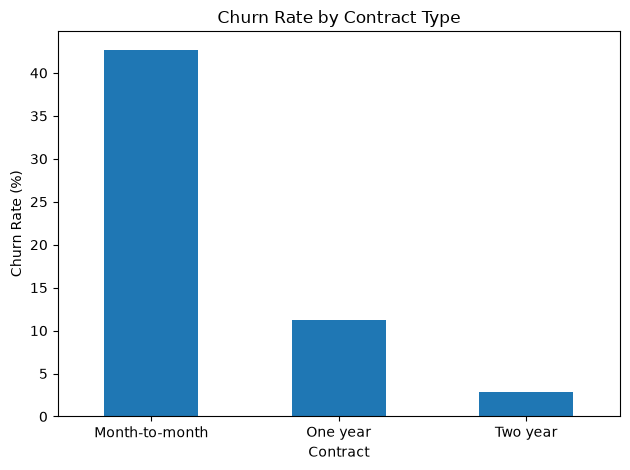

In [15]:
contract_churn = eda.groupby("Contract")["churn_flag"].mean() * 100

contract_churn.plot.bar(
    title="Churn Rate by Contract Type",
    ylabel="Churn Rate (%)",
    rot=0
)
plt.tight_layout()
plt.show()

In [16]:
from scipy.stats import chi2_contingency

features = eda.columns.drop(["customerID", "Churn", "churn_flag"])
group_stats = {}
ranking_rows = []

for feature in features:
    groups = eda[feature]

    if feature == "tenure":
        groups = pd.cut(
            groups,
            bins=[-1, 12, 24, 48, float("inf")],
            labels=["0–12 months", "13–24 months", "25–48 months", "49+ months"],
        )
    elif feature in ["MonthlyCharges", "TotalCharges"] and groups.nunique() > 1:
        groups = pd.qcut(groups, q=4, duplicates="drop")

    counts = pd.crosstab(groups, eda["churn_flag"]).reindex(
        columns=[0, 1], fill_value=0
    )
    customers = counts.sum(axis=1)
    churn_rate = counts[1].div(customers).mul(100)
    group_stats[feature] = pd.DataFrame({
        "Customers": customers,
        "Churned": counts[1],
        "Churn rate (%)": churn_rate,
    })

    # The churn label has two classes, so Cramér's V is sqrt(chi² / n).
    total_customers = int(customers.sum())
    association = float("nan")
    if len(counts) > 1 and counts.sum().gt(0).all():
        chi_square = chi2_contingency(counts, correction=False)[0]
        association = (chi_square / total_customers) ** 0.5

    ranking_rows.append({
        "Feature": feature,
        "Cramér's V": association,
        "Churn rate gap (pp)": churn_rate.max() - churn_rate.min(),
        "Customers analyzed": total_customers,
    })

churn_feature_ranking = (
    pd.DataFrame(ranking_rows)
    .sort_values("Cramér's V", ascending=False)
    .reset_index(drop=True)
)

overall_churn_rate = eda["churn_flag"].mean() * 100
print(f"Overall churn rate: {overall_churn_rate:.2f}%")
display(churn_feature_ranking.round({"Cramér's V": 3, "Churn rate gap (pp)": 2}))

Overall churn rate: 26.54%


,Feature,Cramér's V,Churn rate gap (pp),Customers analyzed
0,Contract,0.410,39.88,7043
1,tenure,0.349,37.93,7043
2,OnlineSecurity,0.347,34.36,7043
3,TechSupport,0.343,34.23,7043
4,InternetService,0.322,34.49,7043
5,PaymentMethod,0.303,30.04,7043
6,OnlineBackup,0.292,32.52,7043
7,DeviceProtection,0.282,31.72,7043
8,TotalCharges,0.239,28.95,7032
9,StreamingMovies,0.231,26.28,7043


### Compare groups within one feature

Change `feature_to_inspect` to any feature in the ranking and rerun this
cell. The dashed line marks the overall churn rate in the dataset.

,Customers,Churned,Churn rate (%)
tenure,,,
0–12 months,2186,1037,47.44
13–24 months,1024,294,28.71
25–48 months,1594,325,20.39
49+ months,2239,213,9.51


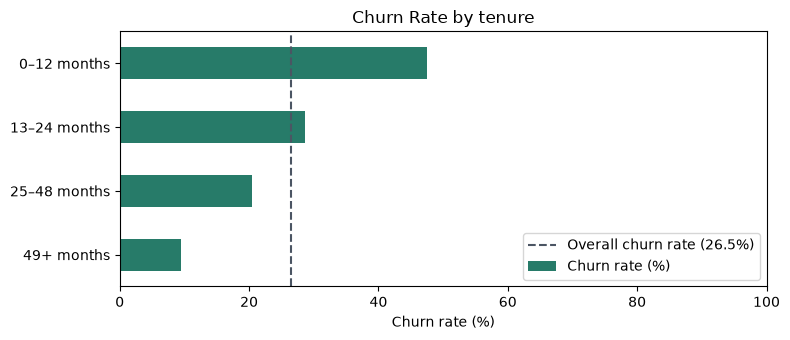

In [17]:
feature_to_inspect = "tenure"
selected_groups = group_stats[feature_to_inspect]

display(selected_groups.round({"Churn rate (%)": 2}))

ax = selected_groups["Churn rate (%)"].plot.barh(
    figsize=(8, 3.5),
    color="#277b69",
    xlim=(0, 100),
    title=f"Churn Rate by {feature_to_inspect}",
)
ax.invert_yaxis()
ax.axvline(
    overall_churn_rate,
    color="#4b5563",
    linestyle="--",
    label=f"Overall churn rate ({overall_churn_rate:.1f}%)",
)
ax.set_xlabel("Churn rate (%)")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()